# Сортировка

После пары вы сможете:

- проследить по шагам сортировку пузырьком, вставками, слиянием, быструю сортировку и сортировку подсчётом;
- сказать, сколько времени и памяти нужно каждой из них;
- выбрать сортировку под задачу и объяснить, где она не подходит;
- пользоваться отсортированным списком: бинарный поиск, два указателя, минимум и максимум, поиск записи по ключу.

## План пары (около 90 минут)

1. Сортировка пузырьком и вставками.
2. Сортировка слиянием.
3. Быстрая сортировка.
4. Сортировка подсчётом.
5. Что выбрать.
6. Квиз: пять вопросов.
7. Зачем сортировать: четыре примера.


## Перед началом

**Как пробовать свои числа.** Запустите ячейку ниже один раз. После этого под каждой сортировкой появится поле: впишите числа через пробел или запятую и нажмите «Отсортировать». Ниже появится каждый шаг.

**Слова, которые встретятся дальше:**

- **Сортировка на месте** переставляет числа внутри того же списка и не заводит второй такой же список.
- **Устойчивая сортировка** оставляет равные элементы в том порядке, в каком они были. Это важно, когда сортируют не числа, а записи: например, студентов по баллу, и среди равных баллов нужно сохранить алфавитный порядок.
- **Что верно после каждого шага** — утверждение, которое алгоритм не нарушает ни на одном шаге. В учебниках его называют инвариантом. По нему проще всего проверить, что алгоритм не ошибается.
- $O(n^2)$ читается «порядка $n$ в квадрате»: если чисел станет в 10 раз больше, работы станет примерно в 100 раз больше. $O(n \log n)$ растёт намного медленнее: для миллиона чисел это около 20 миллионов шагов вместо триллиона.


In [4]:
def read_numbers(text):
    """Превращает строку «5, 2 9» в список [5, 2, 9]."""
    return [int(part) for part in text.replace(",", " ").split()]


def try_sort(sort, example="5 2 9 1 5 6"):
    """Показывает поле для своих чисел и печатает шаги сортировки."""

    def run(text):
        text = text.strip() or example
        try:
            numbers = read_numbers(text)
        except ValueError:
            print("Нужны целые числа через пробел или запятую, например: 5 2 9 1")
            return
        print(f"вход: {numbers}")
        try:
            result = sort(numbers)
        except ValueError as error:
            print(error)
            return
        print(f"результат: {result}")

    try:
        import ipywidgets as widgets
        from IPython.display import display
    except ImportError:
        run(input(f"Числа через пробел (Enter — пример {example}): "))
        return

    field = widgets.Text(value=example, description="Числа:")
    button = widgets.Button(description="Отсортировать")
    output = widgets.Output()

    def on_click(_):
        output.clear_output()
        with output:
            run(field.value)

    button.on_click(on_click)
    display(widgets.HBox([field, button]), output)


## Сортировка пузырьком

**Идея.** Идём по списку слева направо и сравниваем соседей. Если левый больше правого, меняем их местами. За один проход самое большое число доезжает до конца списка — как пузырёк всплывает наверх. Повторяем проходы, пока список не станет упорядоченным.

**Что верно после каждого прохода.** После прохода номер $k$ последние $k$ чисел — самые большие, и они уже стоят по возрастанию. Их больше не трогаем.

**Ранний выход.** Если за проход не случилось ни одного обмена, список уже отсортирован, и дальше идти не нужно.

**Автор и год.** Первое описание — статья Эдварда Френда 1956 года, там метод назван «сортировкой обменами». Название «пузырёк» (bubble sort) впервые появилось в печати в 1962 году у Кеннета Айверсона.

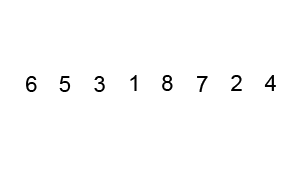


In [1]:
def bubble_sort(arr):
    # Что верно после прохода k: последние k чисел — самые большие и стоят по порядку.
    n = len(arr)
    for i in range(n):
        swapped = False
        print(f"проход {i + 1}, список {arr}")
        for j in range(n - i - 1):
            left, right = arr[j], arr[j + 1]
            if left > right:
                print(f"  меняем местами {left} и {right}")
                arr[j], arr[j + 1] = right, left
                swapped = True
            else:
                print(f"  {left} и {right} уже по порядку")
        if not swapped:
            print("  обменов не было, выходим")
            break
    return arr


In [5]:
bubble_sort([4, 3, 1, 2])


проход 1, список [4, 3, 1, 2]
  меняем местами 4 и 3
  меняем местами 4 и 1
  меняем местами 4 и 2
проход 2, список [3, 1, 2, 4]
  меняем местами 3 и 1
  меняем местами 3 и 2
проход 3, список [1, 2, 3, 4]
  1 и 2 уже по порядку
  обменов не было, выходим


[1, 2, 3, 4]

In [6]:
# Впишите свои числа в поле и нажмите «Отсортировать».
try_sort(bubble_sort)


Output()

**Оценка сложности**

- Время: в худшем и среднем случае $O(n^2)$. Если список уже почти отсортирован, ранний выход даёт $O(n)$.
- Память: $O(1)$, сортирует на месте.
- Устойчивая: равные числа не меняются местами, потому что меняем только при строгом `>`.

**Когда выбирать.** Почти никогда в реальной работе. Пузырёк хорош, чтобы понять, что такое проход, обмен и «что верно после каждого шага».

**Когда не стоит.** Для любого списка длиннее нескольких десятков чисел: вставки делают ту же работу быстрее, а сортировки за $O(n \log n)$ быстрее на порядки.

**Пограничные случаи**

- Пустой список или одно число — сравнивать нечего, список сразу готов.
- Уже отсортированный список — один проход без обменов, затем ранний выход.
- Список по убыванию — худший случай: каждое сравнение заканчивается обменом.


## Сортировка вставками

**Идея.** Левая часть списка, условно, уже упорядочена. Берём следующее число и сдвигаем его влево, пока слева от него не окажется число меньше или равное. Потом берём следующее.

**Что верно перед каждым шагом.** Перед шагом номер $i$ первые $i$ чисел, `arr[:i]`, уже стоят по порядку. Новое число вставляется в эту часть на своё место.

Сдвигаем, только пока левое число строго больше (`>`). Равное число не обгоняет того, кто уже стоял левее, поэтому сортировка устойчивая.

**Автор и год.** Одного автора нет: это самый естественный способ, которым люди раскладывают карты. Для компьютеров метод упомянул Джон Мокли в 1946 году — в первом опубликованном разговоре о компьютерной сортировке.

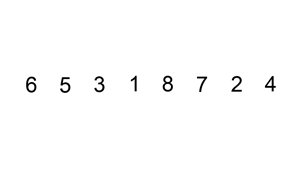


In [7]:
def insertion_sort(arr):
    # Что верно перед шагом i: первые i чисел arr[:i] уже стоят по порядку.
    for i in range(1, len(arr)):
        key = arr[i]
        j = i - 1
        print(f"берём {key} с позиции {i}")
        while j >= 0 and arr[j] > key:
            print(f"  сдвигаем {arr[j]} вправо")
            arr[j + 1] = arr[j]
            j -= 1
        arr[j + 1] = key
        print(f"  ставим {key} на позицию {j + 1}: {arr}")
    return arr


In [8]:
print("случайный порядок")
insertion_sort([4, 3, 1, 2])
print()
print("почти отсортированный список")
insertion_sort([1, 2, 3, 5, 4, 6])


случайный порядок
берём 3 с позиции 1
  сдвигаем 4 вправо
  ставим 3 на позицию 0: [3, 4, 1, 2]
берём 1 с позиции 2
  сдвигаем 4 вправо
  сдвигаем 3 вправо
  ставим 1 на позицию 0: [1, 3, 4, 2]
берём 2 с позиции 3
  сдвигаем 4 вправо
  сдвигаем 3 вправо
  ставим 2 на позицию 1: [1, 2, 3, 4]

почти отсортированный список
берём 2 с позиции 1
  ставим 2 на позицию 1: [1, 2, 3, 5, 4, 6]
берём 3 с позиции 2
  ставим 3 на позицию 2: [1, 2, 3, 5, 4, 6]
берём 5 с позиции 3
  ставим 5 на позицию 3: [1, 2, 3, 5, 4, 6]
берём 4 с позиции 4
  сдвигаем 5 вправо
  ставим 4 на позицию 3: [1, 2, 3, 4, 5, 6]
берём 6 с позиции 5
  ставим 6 на позицию 5: [1, 2, 3, 4, 5, 6]


[1, 2, 3, 4, 5, 6]

In [7]:
# Впишите свои числа в поле и нажмите «Отсортировать».
try_sort(insertion_sort)


Output()

**Оценка сложности**

- Время: в худшем и среднем случае $O(n^2)$. Если список почти отсортирован, $O(n)$: почти ничего не сдвигается.
- Память: $O(1)$, сортирует на месте.
- Устойчивая.

**Когда выбирать.** Маленькие списки, до нескольких десятков чисел. Списки, которые уже почти упорядочены: например, в отсортированный список дописали пару новых значений. Поэтому вставки есть внутри стандартной сортировки Python: короткие куски она досортировывает именно ими.

**Когда не стоит.** Большие списки в случайном порядке: число сдвигов растёт как $n^2$.

**Пограничные случаи**

- `[1, 2, 3, 5, 4, 6]` — сдвигается только пятёрка, остальные шаги ничего не двигают.
- Список по убыванию — худший случай: каждое новое число проезжает до самого начала.
- Равные числа остаются в исходном порядке.


## Сортировка слиянием (merge sort)

**Идея.** Рекурсивно, делим список пополам, каждую половину сортируем тем же способом, а потом сливаем две упорядоченные половины в одну. Слить легко: смотрим на первые числа обеих половин, меньшее переносим в результат и повторяем.

**Что верно при слиянии.** Результат `res` всегда упорядочен, и в каждой половине ещё не взятые числа тоже упорядочены. Поэтому самое маленькое из оставшихся — всегда одно из двух первых.

При равенстве берём число из левой половины (`<=`). Так равные числа не меняются местами, и сортировка остаётся устойчивой.

Слияние создаёт новый список, поэтому это сортировка не на месте.

**Автор и год.** Джон фон Нейман, 1945 год. Подробное описание вышло в отчёте Германа Голдстайна и фон Неймана в 1948 году.

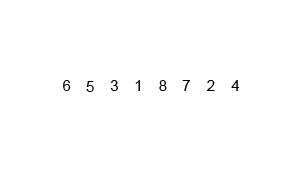


In [8]:
def merge(left, right):
    """Слить два отсортированных списка в один новый устойчиво."""
    # Что верно на каждом шаге: res упорядочен, а left[lf:] и right[rg:] — ещё не взятые
    # и тоже упорядоченные части.
    lf = 0
    rg = 0
    res = []
    while lf < len(left) and rg < len(right):
        if left[lf] <= right[rg]:
            res.append(left[lf])
            lf += 1
        else:
            res.append(right[rg])
            rg += 1
    res.extend(left[lf:])
    res.extend(right[rg:])
    print(f"сливаем {left} и {right} -> {res}")
    return res


def merge_sort(arr):
    if len(arr) <= 1:
        return list(arr)
    mid = len(arr) // 2
    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])
    return merge(left, right)


In [9]:
merge_sort([4, 3, 1, 2])


сливаем [4] и [3] -> [3, 4]
сливаем [1] и [2] -> [1, 2]
сливаем [3, 4] и [1, 2] -> [1, 2, 3, 4]


[1, 2, 3, 4]

In [10]:
# Впишите свои числа в поле и нажмите «Отсортировать».
try_sort(merge_sort)


Output()

**Почему $O(n \log n)$.** Список делится пополам, пока не останутся куски по одному числу: это $\log n$ уровней. На каждом уровне все слияния вместе перебирают $n$ чисел. Итого $n \log n$ — на любом входе, даже в худшем случае.

$$
T(n) = 2T(n/2) + O(n) = O(n \log n)
$$

**Оценка сложности**

- Время: $O(n \log n)$ всегда.
- Память: $O(n)$ на новый список.
- Устойчивая, если сравнивать через `<=`.

**Когда выбирать.** Нужна гарантия $O(n \log n)$ на любом входе. Нужна устойчивость: например, сортируем записи по одному полю и хотим сохранить порядок по другому. Данные не помещаются в память и лежат в файлах: отсортированные куски удобно сливать по частям.

**Когда не стоит.** Памяти мало: нужен дополнительный список такого же размера. Совсем маленькие списки: вставки справятся быстрее.

**Пограничные случаи**

- Если написать `<` вместо `<=`, равное число из правой половины обгонит такое же из левой, и сортировка перестанет быть устойчивой.
- Одна половина закончилась раньше — остаток второй дописываем целиком: он уже упорядочен.
- Пустой список и список из одного числа возвращаются сразу.


## Быстрая сортировка (quicksort)

**Идея.** Выбираем одно число — опорный элемент. Переставляем список так, чтобы слева оказались числа не больше опорного, а справа — не меньше. Потом тем же способом сортируем левую и правую части отдельно.

**Как идёт разбиение.** Два указателя идут навстречу друг другу. Левый останавливается на числе, которое не меньше опорного, правый — на числе, которое не больше. Оба остановились — меняем эти числа местами и идём дальше. Когда указатели встретились, слева от места встречи остались только числа не больше опорного, справа — не меньше.

Опорный элемент выбираем случайно. Если всегда брать первый, на уже отсортированном списке каждое разбиение отрезает всего одно число, и время вырастает до $O(n^2)$.

Сортирует на месте. Равные числа может переставить, поэтому сортировка неустойчивая.

**Автор и год.** Тони Хоар, 1959–1960 годы. Он придумал этот способ в Москве, когда стажировался в МГУ и занимался машинным переводом: слова предложения нужно было упорядочить, прежде чем искать их в словаре на магнитной ленте. Опубликовал в 1961 году.

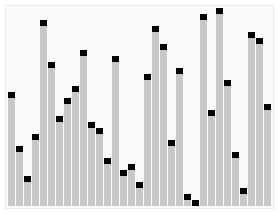


In [9]:
from random import randint


def partition(arr, left, right, pivot_at=None):
    # После разбиения: в arr[left..j] числа не больше опорного, в arr[j+1..right] — не меньше.
    # Опорный берём не с последней позиции: иначе граница может совпасть с right,
    # и отрезок не уменьшится.
    pos = left if pivot_at == "first" else randint(left, right - 1)
    pivot = arr[pos]
    print(f"отрезок [{left}, {right}], опорный элемент {pivot}")
    i = left - 1
    j = right + 1
    while True:
        i += 1
        while arr[i] < pivot:
            i += 1
        j -= 1
        while arr[j] > pivot:
            j -= 1
        if i >= j:
            print(f"  после разбиения: {arr}, граница после позиции {j}")
            return j
        print(f"  меняем местами {arr[i]} и {arr[j]}")
        arr[i], arr[j] = arr[j], arr[i]


def quicksort(arr, left=0, right=None, pivot_at=None):
    if right is None:
        right = len(arr) - 1
    if left < right:
        q = partition(arr, left, right, pivot_at=pivot_at)
        quicksort(arr, left, q, pivot_at=pivot_at)
        quicksort(arr, q + 1, right, pivot_at=pivot_at)
    return arr


In [10]:
from random import seed

print("случайный опорный элемент")
seed(0)
print("итог", quicksort([4, 3, 1, 2]))
print()
print("опорный всегда первый, а список уже отсортирован")
print("итог", quicksort([1, 2, 3, 4, 5, 6], pivot_at="first"))


случайный опорный элемент
отрезок [0, 3], опорный элемент 3
  меняем местами 4 и 2
  меняем местами 3 и 1
  после разбиения: [2, 1, 3, 4], граница после позиции 1
отрезок [0, 1], опорный элемент 2
  меняем местами 2 и 1
  после разбиения: [1, 2, 3, 4], граница после позиции 0
отрезок [2, 3], опорный элемент 3
  после разбиения: [1, 2, 3, 4], граница после позиции 2
итог [1, 2, 3, 4]

опорный всегда первый, а список уже отсортирован
отрезок [0, 5], опорный элемент 1
  после разбиения: [1, 2, 3, 4, 5, 6], граница после позиции 0
отрезок [1, 5], опорный элемент 2
  после разбиения: [1, 2, 3, 4, 5, 6], граница после позиции 1
отрезок [2, 5], опорный элемент 3
  после разбиения: [1, 2, 3, 4, 5, 6], граница после позиции 2
отрезок [3, 5], опорный элемент 4
  после разбиения: [1, 2, 3, 4, 5, 6], граница после позиции 3
отрезок [4, 5], опорный элемент 5
  после разбиения: [1, 2, 3, 4, 5, 6], граница после позиции 4
итог [1, 2, 3, 4, 5, 6]


In [13]:
# Впишите свои числа в поле и нажмите «Отсортировать».
try_sort(quicksort)


Output()

**Оценка сложности**

- Время: в среднем $O(n \log n)$, в худшем $O(n^2)$. Со случайным опорным элементом худший случай почти не встречается.
- Память: сортирует на месте, но рекурсия занимает в среднем $O(\log n)$.
- Неустойчивая.

**Когда выбирать.** Обычные числа в памяти, устойчивость не нужна. Быстрая сортировка не заводит второй список и на практике обычно обгоняет слияние.

**Когда не стоит.** Нужна устойчивость. Нельзя допустить даже редкий медленный случай — тогда надёжнее слияние с его гарантией $O(n \log n)$.

**Пограничные случаи**

- Отсортированный список и опорный «всегда первый» — каждое разбиение отрезает одно число: $n$ уровней рекурсии и $O(n^2)$ сравнений. Это видно во втором примере выше.
- Все числа одинаковые — разбиение всё равно делит отрезок примерно пополам: указатели останавливаются на числах, равных опорному.
- Отрезок из одного числа уже отсортирован, рекурсия на нём останавливается.


#%% md
## Сортировка подсчётом

**Идея.** Числа между собой почти не сравниваем. Один раз проходим по списку и считаем в словаре, сколько раз встретилось каждое значение: увидели 3 — прибавили единицу к `count[3]`. Потом упорядочиваем только разные значения и выписываем каждое столько раз, сколько насчитали.

**Зачем `sorted(count)`.** Словарь в Python хранит ключи в порядке появления, а не по возрастанию. Поэтому ключи нужно упорядочить, но это только разные значения, а их обычно намного меньше, чем чисел.

**Когда это выгодно.** Когда в данных много повторов: оценки от 1 до 5, возраст, города, статусы заказов.

**Что верно после подсчёта.** `count[v]` равен тому, сколько раз $v$ встречается в списке. Поэтому, выписав разные значения по порядку, мы получим каждое ровно столько раз, сколько оно было.

Результат — новый список, это сортировка не на месте.

**Автор и год.** Гарольд Сьюард, 1954 год, магистерская работа в Массачусетском технологическом институте (MIT).

**Отличие от классики.** У Сьюарда счётчики лежат в массиве, и значения обходят подряд от наименьшего к наибольшему, как на анимации. Со словарём не нужно заранее знать диапазон значений, а упорядочиваются только те значения, которые встретились.


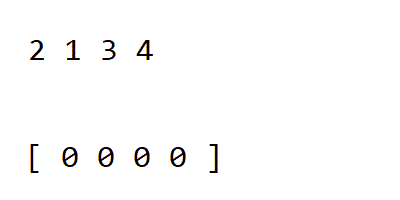


In [13]:
def counting_sort(arr):
    # Что верно после подсчёта: count[v] — сколько раз значение v встречается в arr.
    count = {}
    for x in arr:
        count[x] = count.get(x, 0) + 1
    print(f"посчитали, ключи в порядке появления: {count}")
    keys = sorted(count)
    print(f"разных значений {len(keys)} из {len(arr)}, упорядочиваем только их: {keys}")
    result = []
    for value in keys:
        print(f"  {value}: {count[value]}")
        result.extend([value] * count[value])
    return result

In [16]:
from random import randint
print(counting_sort([4, 3, 1, 2, 3]))
print()
print("отрицательные числа: номер счётчика отсчитываем от минимума")
print(counting_sort([3, -2, 0, -2]))
print()
print("всего 10 числе, но большое кол-во элементов")
print(counting_sort([randint(0,10) for x in range(10000)]))


посчитали, ключи в порядке появления: {4: 1, 3: 2, 1: 1, 2: 1}
разных значений 4 из 5, упорядочиваем только их: [1, 2, 3, 4]
  1: 1
  2: 1
  3: 2
  4: 1
[1, 2, 3, 3, 4]

отрицательные числа: номер счётчика отсчитываем от минимума
посчитали, ключи в порядке появления: {3: 1, -2: 2, 0: 1}
разных значений 3 из 4, упорядочиваем только их: [-2, 0, 3]
  -2: 2
  0: 1
  3: 1
[-2, -2, 0, 3]

всего 10 числе, но большое кол-во элементов
посчитали, ключи в порядке появления: {8: 930, 4: 852, 6: 905, 1: 941, 7: 857, 2: 886, 9: 954, 0: 938, 5: 920, 3: 930, 10: 887}
разных значений 11 из 10000, упорядочиваем только их: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
  0: 938
  1: 941
  2: 886
  3: 930
  4: 852
  5: 920
  6: 905
  7: 857
  8: 930
  9: 954
  10: 887
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [16]:
# Впишите свои числа в поле и нажмите «Отсортировать».
try_sort(counting_sort)


Output()

**Оценка сложности**

- Время: $O(n + k)$, где $n$ — сколько чисел в списке, $k$ — сколько разных значений возможно, от минимума до максимума.
- Память: $O(k)$ на счётчики.
- Сравнений нет. Поэтому подсчёт может работать быстрее, чем $O(n \log n)$: эта граница касается только сортировок, которые сравнивают числа между собой.

**Когда выбирать.** Много целых чисел из маленького диапазона: миллион оценок от 1 до 5 сортируется за один проход.

**Когда не стоит.** Дробные числа и строки: их нельзя напрямую сделать номером счётчика. Большой разброс: два числа, 1 и 1 000 000 000, потребуют миллиард счётчиков.

**На практике.**
- Сортировка строковых значений
- Сортировка значений, где кол-во уникальных значений в списке меньше чем √N

**Пограничные случаи**

- Отрицательные числа: номер счётчика считаем от минимума, `x - low`.
- Большой разброс при малом количестве чисел: счётчиков намного больше, чем самих чисел. Функция выше отказывается заводить больше 100 000 счётчиков.
- Пустой список сразу возвращается пустым.
- Если нужно сортировать не числа, а записи по ключу, используют вариант с накопленными суммами: он тоже сохраняет порядок равных ключей.


## Что выбрать

| Сортировка | Время обычно | Время в худшем | Память | Устойчивая | На месте |
| --- | --- | --- | --- | --- | --- |
| Пузырьком | $O(n^2)$ | $O(n^2)$ | $O(1)$ | да | да |
| Вставками | $O(n^2)$ | $O(n^2)$ | $O(1)$ | да | да |
| Слиянием | $O(n \log n)$ | $O(n \log n)$ | $O(n)$ | да | нет |
| Быстрая | $O(n \log n)$ | $O(n^2)$ | $O(\log n)$ | нет | да |
| Подсчётом | $O(n + k)$ | $O(n + k)$ | $O(k)$ | да | нет |

**Коротко:**

- список маленький или почти отсортирован — вставки;
- нужна устойчивость или гарантия $O(n \log n)$ — слияние;
- обычные числа в памяти, устойчивость не важна — быстрая сортировка со случайным опорным элементом;
- целые числа из небольшого диапазона — подсчёт;
- пузырёк — чтобы понять идею, не для работы.

В Python на практике пишут `sorted(numbers)` или `numbers.sort()`. Внутри — Timsort (Тим Петерс, 2002): он соединяет вставки на коротких кусках и слияние на длинных, устойчив и работает за $O(n \log n)$.


## Квиз

Пять вопросов по сортировкам. Наведите камеру телефона на QR-код на экране или откройте ahaslides.com и введите код `FJQ4R`. Отвечать можно, пока вопрос на экране. После таблицы лидеров назовём победителя.

## Зачем сортировать: четыре примера

Сортировка редко нужна сама по себе. Обычно её делают один раз, чтобы потом много раз быстро отвечать на вопросы. Ниже — четыре приёма, которые работают только на отсортированном списке и ещё не раз встретятся в курсе.

### Бинарный поиск

**Идея.** Как поиск слова в бумажном словаре: открываем середину, смотрим, левее или правее нужное слово, и отбрасываем половину. За каждое сравнение область поиска уменьшается вдвое.

**Что верно на каждом шаге.** Все числа левее `left` меньше искомого, все числа начиная с `right` — не меньше. Ответ всегда лежит между `left` и `right`.

Функция возвращает позицию первого числа, которое не меньше искомого. Если искомое больше всех, вернётся длина списка.

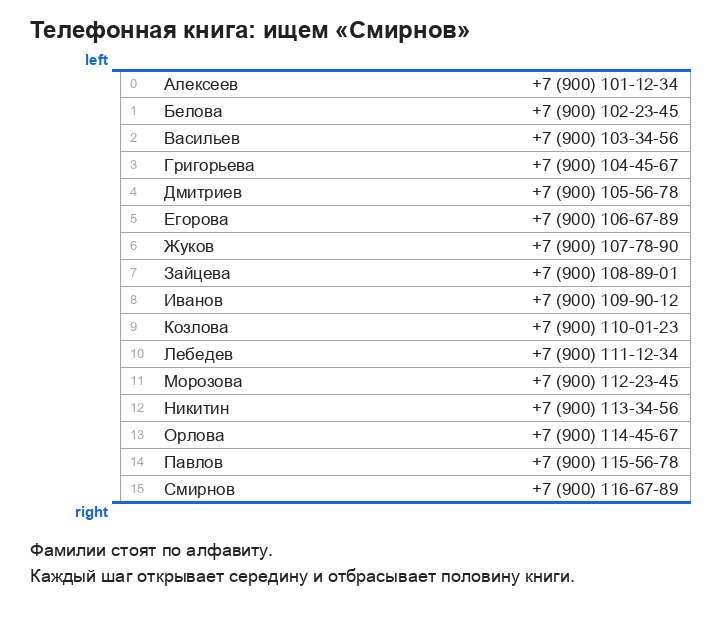

**Автор и год.** Идею впервые упомянул Джон Мокли в 1946 году. До 1960 года все опубликованные версии работали только для списков длиной $2^k - 1$. Версию для любой длины опубликовал Деррик Лемер в 1960 году.

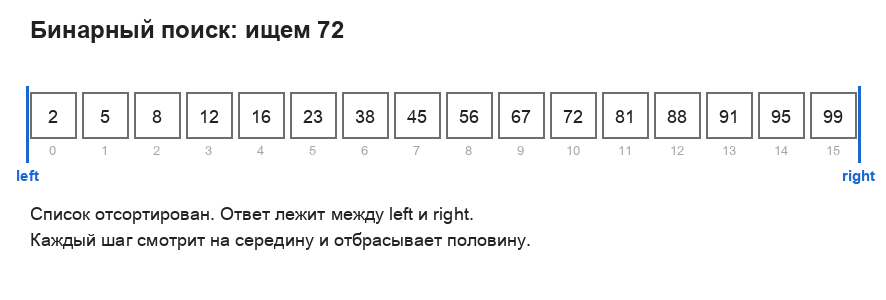

In [11]:
def binary_search(arr, target):
    # Что верно на каждом шаге: arr[:left] < target <= arr[right:].
    left, right = 0, len(arr)
    while left < right:
        mid = (left + right) // 2
        print(f"ищем {target}: left={left}, mid={mid}, right={right}, arr[mid]={arr[mid]}")
        if arr[mid] < target:
            left = mid + 1
        else:
            right = mid
    return left


In [12]:
data = [1, 3, 4, 7, 8, 10, 12, 15]
print("первое число не меньше 10 стоит на позиции", binary_search(data, 10))
print()
print("первое число не меньше 9 стоит на позиции", binary_search(data, 9))


ищем 10: left=0, mid=4, right=8, arr[mid]=8
ищем 10: left=5, mid=6, right=8, arr[mid]=12
ищем 10: left=5, mid=5, right=6, arr[mid]=10
первое число не меньше 10 стоит на позиции 5

ищем 9: left=0, mid=4, right=8, arr[mid]=8
ищем 9: left=5, mid=6, right=8, arr[mid]=12
ищем 9: left=5, mid=5, right=6, arr[mid]=10
первое число не меньше 9 стоит на позиции 5


**Оценка сложности**

- Время: $O(\log n)$. Для миллиона чисел — около 20 сравнений.
- Память: $O(1)$.

**Когда выбирать.** Один список и много поисков: отсортировали один раз за $O(n \log n)$, дальше каждый поиск за $O(\log n)$.

**Когда не стоит.** Нужен один поиск в неотсортированном списке: просмотреть его целиком за $O(n)$ быстрее, чем сначала сортировать. Список часто меняется: вставка в середину сдвигает все числа правее, это $O(n)$.

**Пограничные случаи**

- Искомое больше всех чисел — ответ `len(arr)`, и обращаться к `arr[ответ]` нельзя.
- Несколько одинаковых чисел — вернётся позиция первого из них.
- Пустой список — ответ 0.
- Самая частая ошибка — на единицу в границах: `right = mid` или `right = mid - 1`, `left < right` или `left <= right`. Печать границ на каждом шаге сразу её показывает.


### Минимум, медиана, перцентили, максимум

**Идея.** В отсортированном списке «число по порядку» — это просто число на нужной позиции. Минимум стоит первым, максимум — последним, медиана — посередине. Все они — частные случаи перцентиля.

**Перцентиль** $p$ — значение, ниже которого лежит $p$ процентов данных. Минимум — 0-й перцентиль, медиана — 50-й, максимум — 100-й. 90-й перцентиль говорит: 90% значений не больше него. Так измеряют скорость сайтов и сервисов.

**Как найти позицию.** В отсортированном списке из $n$ чисел $p$-й перцентиль стоит на позиции $(n - 1) \cdot p / 100$. Если позиция дробная, например 5,5, берём значение между соседями пропорционально: 5,5 — ровно посередине между 5-м и 6-м числом. Так же по умолчанию считают NumPy и функция Excel ПРОЦЕНТИЛЬ.ВКЛ. Поэтому при чётном количестве чисел медиана — среднее двух центральных.

**Пример.** Время ответа сайта на 12 запросов, в миллисекундах. Одиннадцать запросов уложились в 95–130 мс, один висел 2300 мс.

**Почему не среднее.** Среднему сортировка не нужна: хватает одного прохода. Но один медленный запрос тянет его вверх: здесь среднее выходит около 292 мс, хотя так долго ждал только один запрос из 12. Медиана и перцентили такой выброс почти не замечают, а для них нужен порядок.

**Автор и год.** Медианой пользовались задолго до компьютеров. Слово «перцентиль» ввёл Фрэнсис Гальтон в 1885 году.

Анимация проходит те же шаги, что печатает ячейка ниже: сначала сортировка, потом 0-й, 50-й, 90-й, 99-й и 100-й перцентили по индексу.

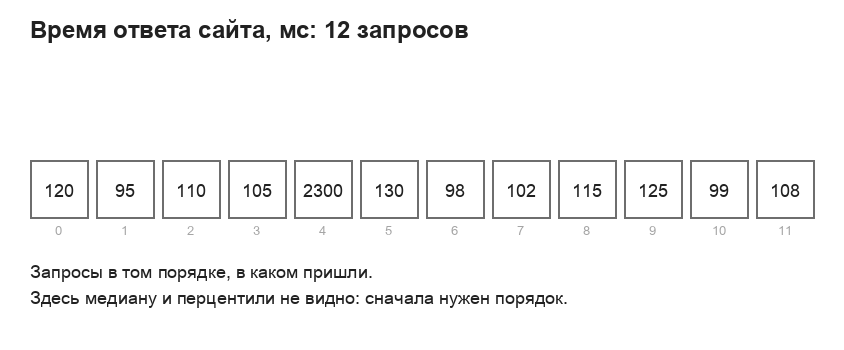


In [31]:
def percentile(sorted_arr, p):
    # Позиция от 0 до n - 1; между соседями значение растёт пропорционально.
    position = (len(sorted_arr) - 1) * p / 100
    lower = int(position)
    upper = min(lower + 1, len(sorted_arr) - 1)
    fraction = position - lower
    value = sorted_arr[lower] + (sorted_arr[upper] - sorted_arr[lower]) * fraction
    if fraction == 0:
        print(f"{p}-й перцентиль: позиция {lower}, там {value:g}")
    else:
        print(
            f"{p}-й перцентиль: позиция {position:g}, "
            f"между [{lower}] = {sorted_arr[lower]} и [{upper}] = {sorted_arr[upper]} -> {value:g}"
        )
    return value

In [32]:
response_ms = [120, 95, 110, 105, 2300, 130, 98, 102, 115, 125, 99, 108]
times = sorted(response_ms)
print("отсортировали:", times)
print()
for p in (0, 50, 90, 99, 100):
    percentile(times, p)


отсортировали: [95, 98, 99, 102, 105, 108, 110, 115, 120, 125, 130, 2300]

0-й перцентиль: позиция 0, там 95
50-й перцентиль: позиция 5.5, между [5] = 108 и [6] = 110 -> 109
90-й перцентиль: позиция 9.9, между [9] = 125 и [10] = 130 -> 129.5
99-й перцентиль: позиция 10.89, между [10] = 130 и [11] = 2300 -> 2061.3
100-й перцентиль: позиция 11, там 2300
